# 04. Model Comparison

This notebook compares the **Philippine-only baseline LSTM** and the **transfer-learning LSTM** on the same held-out Philippine test sequences.

The initial section reloads the saved models and Philippine preprocessing objects, recreates the exact test sequences, recalculates metrics, and prepares paired error differences.

**The final statistical test is intentionally not selected yet.** It will be chosen after inspecting the paired error differences.

## 1. Import the Libraries

In [ ]:
import os
os.environ["KERAS_BACKEND"] = "torch"

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import keras
from keras.models import load_model

Keras version: 3.16.0.dev2026092704
Keras backend: torch


## 2. Reproducibility Seed

In [2]:
RANDOM_SEED = 42
keras.utils.set_random_seed(RANDOM_SEED)
print("Random seed:", RANDOM_SEED)

Random seed: 42


## 3. Define Project Paths

In [3]:
PH_BASELINE_MODEL_PATH = Path("../models/ph_baseline.keras")
TRANSFER_MODEL_PATH = Path("../models/transfer_final.keras")
PH_SCALER_PATH = Path("../models/ph_scaler.pkl")
PH_DATA_PATH = Path("../data/PH_data.csv")
PH_BASELINE_METRICS_PATH = Path("../results/ph_baseline_metrics.csv")
TRANSFER_METRICS_PATH = Path("../results/transfer_metrics.csv")

paths_to_check = {
    "PH baseline model": PH_BASELINE_MODEL_PATH,
    "Transfer model": TRANSFER_MODEL_PATH,
    "PH scaler": PH_SCALER_PATH,
    "PH data": PH_DATA_PATH,
    "PH baseline metrics": PH_BASELINE_METRICS_PATH,
    "Transfer metrics": TRANSFER_METRICS_PATH
}

for name, path in paths_to_check.items():
    print(f"{name} exists:", path.exists())

missing = [name for name, path in paths_to_check.items() if not path.exists()]
if missing:
    raise FileNotFoundError("Missing required project files: " + ", ".join(missing))

PH baseline model exists: True
Transfer model exists: True
PH scaler exists: True
PH data exists: True
PH baseline metrics exists: True
Transfer metrics exists: True


## 4. Load the Saved Models

In [4]:
ph_baseline_model = load_model(PH_BASELINE_MODEL_PATH)
transfer_model = load_model(TRANSFER_MODEL_PATH)

print("Philippine baseline model loaded.")
print("Transfer-learning model loaded.")
print("\nPH baseline input/output:")
print(ph_baseline_model.input_shape, "->", ph_baseline_model.output_shape)
print("\nTransfer model input/output:")
print(transfer_model.input_shape, "->", transfer_model.output_shape)

Philippine baseline model loaded.
Transfer-learning model loaded.

PH baseline input/output:
(None, 6, 2) -> (None, 2)

Transfer model input/output:
(None, 6, 2) -> (None, 2)


## 5. Load Saved Metric Tables

In [5]:
ph_baseline_metrics = pd.read_csv(PH_BASELINE_METRICS_PATH)
transfer_metrics = pd.read_csv(TRANSFER_METRICS_PATH)
print("Philippine-only baseline metrics:")
display(ph_baseline_metrics)
print("\nTransfer-learning metrics:")
display(transfer_metrics)

Philippine-only baseline metrics:


,Variable,MAE,RMSE,R2
0,Water pH,0.014403,0.018859,0.917840
1,Water Temperature,0.116763,0.160331,0.991114



Transfer-learning metrics:


,Variable,MAE,RMSE,R2
0,Water pH,0.022978,0.028046,0.818299
1,Water Temperature,0.158181,0.204537,0.985538


## 6. Create the Overall Metric Comparison Table

In [6]:
ph_metrics_copy = ph_baseline_metrics.copy()
ph_metrics_copy.insert(0, "Model", "PH-Only Baseline")
transfer_metrics_copy = transfer_metrics.copy()
transfer_metrics_copy.insert(0, "Model", "Transfer Learning")
model_metric_comparison = pd.concat([ph_metrics_copy, transfer_metrics_copy], ignore_index=True)
model_metric_comparison

,Model,Variable,MAE,RMSE,R2
0,PH-Only Baseline,Water pH,0.014403,0.018859,0.917840
1,PH-Only Baseline,Water Temperature,0.116763,0.160331,0.991114
2,Transfer Learning,Water pH,0.022978,0.028046,0.818299
3,Transfer Learning,Water Temperature,0.158181,0.204537,0.985538


## 7. Reload and Prepare the Philippine Dataset

In [7]:
ph_df = pd.read_csv(PH_DATA_PATH)
ph_work = ph_df.rename(columns={
    "Date & Time": "created_date",
    "pH": "water_pH",
    "Water Temp (°C)": "water_temp"
}).copy()
ph_work["created_date"] = pd.to_datetime(ph_work["created_date"], format="%Y-%m-%d %H:%M")
ph_work = ph_work.sort_values("created_date").reset_index(drop=True)
ph_model = ph_work[["created_date", "water_pH", "water_temp"]].copy()
print("Rows:", len(ph_model))
print("First timestamp:", ph_model["created_date"].min())
print("Last timestamp:", ph_model["created_date"].max())

Rows: 288
First timestamp: 2026-09-22 00:00:00
Last timestamp: 2026-10-03 23:00:00


## 8. Recreate the Exact Philippine Chronological Split

In [8]:
ph_total_rows = len(ph_model)
ph_train_end = int(ph_total_rows * 0.70)
ph_val_end = int(ph_total_rows * 0.85)
ph_train_df = ph_model.iloc[:ph_train_end].copy()
ph_val_df = ph_model.iloc[ph_train_end:ph_val_end].copy()
ph_test_df = ph_model.iloc[ph_val_end:].copy()
print("Training rows:", len(ph_train_df))
print("Validation rows:", len(ph_val_df))
print("Test rows:", len(ph_test_df))
print("\nTest period:")
print(ph_test_df["created_date"].min(), "to", ph_test_df["created_date"].max())

Training rows: 201
Validation rows: 43
Test rows: 44

Test period:
2026-10-02 04:00:00 to 2026-10-03 23:00:00


## 9. Load the Philippine Scaler and Recreate Test Sequences

In [9]:
ph_scaler = joblib.load(PH_SCALER_PATH)
ph_test_scaled = ph_scaler.transform(ph_test_df[["water_pH", "water_temp"]])
PH_SEQUENCE_LENGTH = 6

def create_sequences(scaled_values, sequence_length):
    X, y = [], []
    for i in range(sequence_length, len(scaled_values)):
        X.append(scaled_values[i-sequence_length:i])
        y.append(scaled_values[i])
    return np.array(X), np.array(y)

X_ph_test, y_ph_test = create_sequences(ph_test_scaled, PH_SEQUENCE_LENGTH)
print("X_ph_test:", X_ph_test.shape)
print("y_ph_test:", y_ph_test.shape)

X_ph_test: (38, 6, 2)
y_ph_test: (38, 2)


## 10. Generate Predictions from Both Saved Models

In [10]:
baseline_pred_scaled = ph_baseline_model.predict(X_ph_test, verbose=0)
transfer_pred_scaled = transfer_model.predict(X_ph_test, verbose=0)
print("Baseline prediction shape:", baseline_pred_scaled.shape)
print("Transfer prediction shape:", transfer_pred_scaled.shape)
print("Actual target shape:", y_ph_test.shape)

Baseline prediction shape: (38, 2)
Transfer prediction shape: (38, 2)
Actual target shape: (38, 2)


## 11. Inverse Transform Actual and Predicted Values

In [11]:
actual_original = ph_scaler.inverse_transform(y_ph_test)
baseline_pred_original = ph_scaler.inverse_transform(baseline_pred_scaled)
transfer_pred_original = ph_scaler.inverse_transform(transfer_pred_scaled)
actual_ph = actual_original[:,0]
actual_temp = actual_original[:,1]
baseline_ph = baseline_pred_original[:,0]
baseline_temp = baseline_pred_original[:,1]
transfer_ph = transfer_pred_original[:,0]
transfer_temp = transfer_pred_original[:,1]
print("First 5 actual values:")
print(actual_original[:5])
print("\nFirst 5 PH-only predictions:")
print(baseline_pred_original[:5])
print("\nFirst 5 transfer predictions:")
print(transfer_pred_original[:5])

First 5 actual values:
[[ 7.67 30.3 ]
 [ 7.69 30.9 ]
 [ 7.72 31.5 ]
 [ 7.74 32.1 ]
 [ 7.75 32.5 ]]

First 5 PH-only predictions:
[[ 7.68547   30.267817 ]
 [ 7.713464  30.92832  ]
 [ 7.7335773 31.508442 ]
 [ 7.7519627 32.029854 ]
 [ 7.767193  32.49725  ]]

First 5 transfer predictions:
[[ 7.675646  30.036741 ]
 [ 7.7056913 30.708487 ]
 [ 7.7327275 31.34898  ]
 [ 7.758133  31.89902  ]
 [ 7.780798  32.406597 ]]


## 12. Recalculate Metrics from the Saved Models

In [12]:
def regression_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    return mae, rmse, r2

baseline_ph_metrics = regression_metrics(actual_ph, baseline_ph)
transfer_ph_metrics = regression_metrics(actual_ph, transfer_ph)
baseline_temp_metrics = regression_metrics(actual_temp, baseline_temp)
transfer_temp_metrics = regression_metrics(actual_temp, transfer_temp)
print("WATER pH")
print("PH-only baseline:", baseline_ph_metrics)
print("Transfer learning:", transfer_ph_metrics)
print("\nWATER TEMPERATURE")
print("PH-only baseline:", baseline_temp_metrics)
print("Transfer learning:", transfer_temp_metrics)

WATER pH
PH-only baseline: (0.014402973275435523, np.float64(0.01885895112668206), 0.9178401359336488)
Transfer learning: (0.022977913304379028, np.float64(0.028045673959904788), 0.8182993822589595)

WATER TEMPERATURE
PH-only baseline: (0.11676285392359678, np.float64(0.1603311556748475), 0.9911138718608734)
Transfer learning: (0.15818147157367923, np.float64(0.20453656015956012), 0.9855383242051322)


## 13. Calculate Paired Absolute Errors

In [13]:
baseline_ph_abs_error = np.abs(actual_ph - baseline_ph)
transfer_ph_abs_error = np.abs(actual_ph - transfer_ph)
baseline_temp_abs_error = np.abs(actual_temp - baseline_temp)
transfer_temp_abs_error = np.abs(actual_temp - transfer_temp)
print("Number of paired pH errors:", len(baseline_ph_abs_error))
print("Number of paired temperature errors:", len(baseline_temp_abs_error))

Number of paired pH errors: 38
Number of paired temperature errors: 38


## 14. Create the Per-Sequence Error Table

In [14]:
error_comparison = pd.DataFrame({
    "Test Sequence": np.arange(len(actual_ph)),
    "Actual pH": actual_ph,
    "PH Baseline Prediction": baseline_ph,
    "PH Transfer Prediction": transfer_ph,
    "PH Baseline Absolute Error": baseline_ph_abs_error,
    "PH Transfer Absolute Error": transfer_ph_abs_error,
    "Actual Temperature": actual_temp,
    "Temperature Baseline Prediction": baseline_temp,
    "Temperature Transfer Prediction": transfer_temp,
    "Temperature Baseline Absolute Error": baseline_temp_abs_error,
    "Temperature Transfer Absolute Error": transfer_temp_abs_error
})
error_comparison.head(10)

,Test Sequence,Actual pH,PH Baseline Prediction,PH Transfer Prediction,PH Baseline Absolute Error,PH Transfer Absolute Error,Actual Temperature,Temperature Baseline Prediction,Temperature Transfer Prediction,Temperature Baseline Absolute Error,Temperature Transfer Absolute Error
0,0,7.67,7.685470,7.675646,0.015470,0.005646,30.3,30.267817,30.036741,0.032183,0.263259
1,1,7.69,7.713464,7.705691,0.023464,0.015691,30.9,30.928320,30.708487,0.028320,0.191513
2,2,7.72,7.733577,7.732728,0.013577,0.012728,31.5,31.508442,31.348980,0.008442,0.151020
3,3,7.74,7.751963,7.758133,0.011963,0.018133,32.1,32.029854,31.899019,0.070146,0.200981
4,4,7.75,7.767193,7.780798,0.017193,0.030798,32.5,32.497250,32.406597,0.002750,0.093403
5,5,7.76,7.772565,7.791781,0.012565,0.031781,32.7,32.718933,32.670013,0.018933,0.029987
6,6,7.76,7.771106,7.792222,0.011106,0.032222,32.8,32.694851,32.643787,0.105149,0.156213
7,7,7.76,7.766192,7.788026,0.006192,0.028026,32.7,32.586689,32.540108,0.113311,0.159892
8,8,7.75,7.758489,7.778576,0.008489,0.028576,32.3,32.361473,32.277336,0.061473,0.022664
9,9,7.74,7.741140,7.759264,0.001140,0.019264,31.7,31.859777,31.727188,0.159777,0.027188


## 15. Calculate Paired Error Differences

Positive values mean transfer learning produced the larger absolute error. Negative values mean transfer learning produced the smaller absolute error.

In [15]:
ph_error_difference = transfer_ph_abs_error - baseline_ph_abs_error
temp_error_difference = transfer_temp_abs_error - baseline_temp_abs_error
print("pH error-difference summary:")
print(pd.Series(ph_error_difference).describe())
print("\nTemperature error-difference summary:")
print(pd.Series(temp_error_difference).describe())

pH error-difference summary:
count    38.000000
mean      0.008575
std       0.012212
min      -0.021646
25%      -0.000410
50%       0.011515
75%       0.019156
max       0.024928
dtype: float64

Temperature error-difference summary:
count    38.000000
mean      0.041419
std       0.142114
min      -0.406689
25%       0.010849
50%       0.044161
75%       0.133338
max       0.301441
dtype: float64


## 16. Count Sequence-Level Wins

In [16]:
ph_baseline_wins = np.sum(baseline_ph_abs_error < transfer_ph_abs_error)
ph_transfer_wins = np.sum(transfer_ph_abs_error < baseline_ph_abs_error)
ph_ties = np.sum(np.isclose(baseline_ph_abs_error, transfer_ph_abs_error))

temp_baseline_wins = np.sum(baseline_temp_abs_error < transfer_temp_abs_error)
temp_transfer_wins = np.sum(transfer_temp_abs_error < baseline_temp_abs_error)
temp_ties = np.sum(np.isclose(baseline_temp_abs_error, transfer_temp_abs_error))

print("WATER pH")
print("PH-only wins:", ph_baseline_wins)
print("Transfer wins:", ph_transfer_wins)
print("Ties:", ph_ties)
print("\nWATER TEMPERATURE")
print("PH-only wins:", temp_baseline_wins)
print("Transfer wins:", temp_transfer_wins)
print("Ties:", temp_ties)

WATER pH
PH-only wins: 28
Transfer wins: 10
Ties: 0

WATER TEMPERATURE
PH-only wins: 29
Transfer wins: 9
Ties: 0


## 17. Visualize the Paired Error Differences

These histograms help inspect the shape of the paired error differences before choosing the final statistical comparison test.

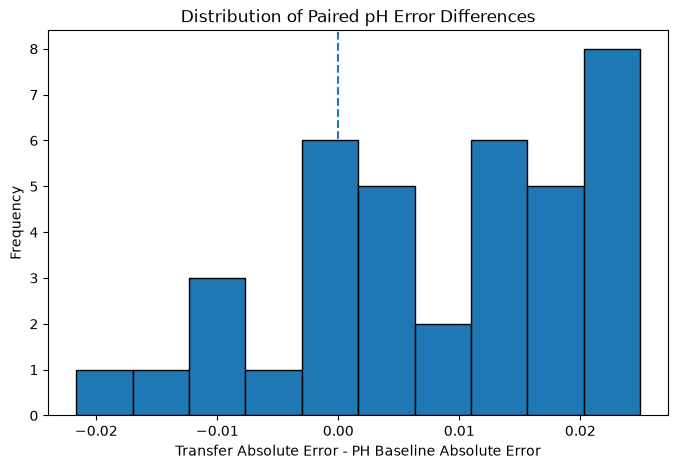

In [17]:
plt.figure(figsize=(8,5))
plt.hist(ph_error_difference, bins=10, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.xlabel("Transfer Absolute Error - PH Baseline Absolute Error")
plt.ylabel("Frequency")
plt.title("Distribution of Paired pH Error Differences")
plt.show()

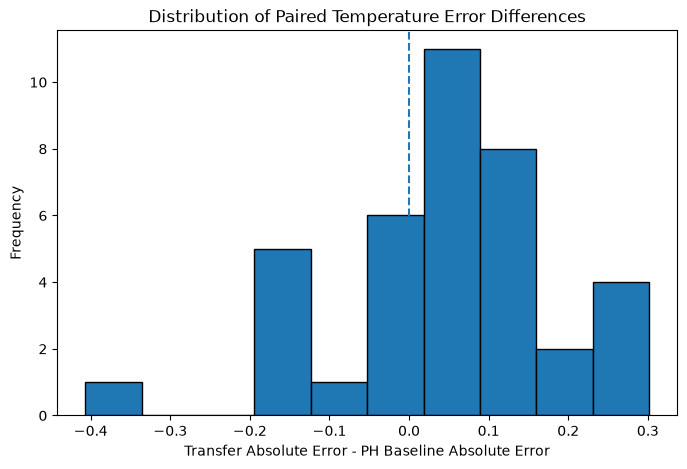

In [18]:
plt.figure(figsize=(8,5))
plt.hist(temp_error_difference, bins=10, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.xlabel("Transfer Absolute Error - PH Baseline Absolute Error")
plt.ylabel("Frequency")
plt.title("Distribution of Paired Temperature Error Differences")
plt.show()

## STOP POINT — Send These Results Before Continuing

Do not run a statistical significance test yet.

Please send:

1. Path-check output
2. Loaded model input/output shapes
3. Saved metric tables
4. Recalculated metrics from Step 12
5. Paired-error counts from Step 13
6. Error-difference summaries from Step 15
7. Sequence-level wins/ties from Step 16
8. Both error-difference histograms from Step 17

After these results are reviewed, the next section will choose and run the appropriate paired statistical test, interpret it separately for pH and temperature, create the final comparison table, and save the model-comparison outputs.

## 18. Normality Test for Paired Error Differences

Before selecting the statistical comparison test, the distribution of paired absolute-error differences is assessed using the Shapiro-Wilk normality test.

The null hypothesis of the Shapiro-Wilk test is that the paired differences are normally distributed.

A significance level of 0.05 is used:

- p-value > 0.05: normality is not rejected
- p-value ≤ 0.05: normality is rejected

The result will determine whether a paired t-test or a non-parametric Wilcoxon signed-rank test is more appropriate.

In [19]:
from scipy.stats import shapiro

In [20]:
ph_shapiro_stat, ph_shapiro_p = shapiro(
    ph_error_difference
)

temp_shapiro_stat, temp_shapiro_p = shapiro(
    temp_error_difference
)

print("WATER pH")
print("Shapiro-Wilk statistic:", ph_shapiro_stat)
print("p-value:", ph_shapiro_p)

print("\nWATER TEMPERATURE")
print("Shapiro-Wilk statistic:", temp_shapiro_stat)
print("p-value:", temp_shapiro_p)

WATER pH
Shapiro-Wilk statistic: 0.9404957107512473
p-value: 0.043473816759875036

WATER TEMPERATURE
Shapiro-Wilk statistic: 0.9473602543360591
p-value: 0.07289456509632085


In [21]:
alpha = 0.05

print("NORMALITY DECISION")

if ph_shapiro_p > alpha:
    print(
        "pH: normality is not rejected."
    )
else:
    print(
        "pH: normality is rejected."
    )

if temp_shapiro_p > alpha:
    print(
        "Temperature: normality is not rejected."
    )
else:
    print(
        "Temperature: normality is rejected."
    )

NORMALITY DECISION
pH: normality is rejected.
Temperature: normality is not rejected.


## 20. Statistical Test Selection

The normality of the paired absolute-error differences was assessed using the Shapiro-Wilk test.

For water pH, the Shapiro-Wilk test produced a p-value of 0.0435, which is below the 0.05 significance level. Therefore, normality was rejected for the pH error differences.

For water temperature, the Shapiro-Wilk test produced a p-value of 0.0729, which is above the 0.05 significance level. Therefore, normality was not rejected for the temperature error differences.

Based on these results:

- the Wilcoxon signed-rank test is used for water pH;
- the paired t-test is used for water temperature.

Both tests compare the paired absolute prediction errors of the Philippine-only baseline and the transfer-learning model on the same 38 held-out test sequences.

In [22]:
from scipy.stats import wilcoxon, ttest_rel

## 22. Water pH Statistical Comparison

Because the paired pH error differences were not normally distributed, the Wilcoxon signed-rank test is used.

The null hypothesis is that there is no systematic difference between the absolute prediction errors of the Philippine-only baseline and the transfer-learning model.

In [23]:
ph_wilcoxon_stat, ph_wilcoxon_p = wilcoxon(
    baseline_ph_abs_error,
    transfer_ph_abs_error
)

print("WATER pH - Wilcoxon Signed-Rank Test")
print("Statistic:", ph_wilcoxon_stat)
print("p-value:", ph_wilcoxon_p)

WATER pH - Wilcoxon Signed-Rank Test
Statistic: 129.0
p-value: 0.000261875509750098


## 23. Water Temperature Statistical Comparison

Because normality was not rejected for the paired temperature error differences, a paired t-test is used.

The null hypothesis is that the mean absolute prediction error is the same for the Philippine-only baseline and the transfer-learning model.

In [24]:
temp_t_stat, temp_t_p = ttest_rel(
    baseline_temp_abs_error,
    transfer_temp_abs_error
)

print("WATER TEMPERATURE - Paired t-Test")
print("t-statistic:", temp_t_stat)
print("p-value:", temp_t_p)

WATER TEMPERATURE - Paired t-Test
t-statistic: -1.7965945561477181
p-value: 0.08056790660385837


In [25]:
alpha = 0.05

print("STATISTICAL DECISIONS")

if ph_wilcoxon_p < alpha:
    print(
        "pH: significant difference between the two models."
    )
else:
    print(
        "pH: no statistically significant difference between the two models."
    )

if temp_t_p < alpha:
    print(
        "Temperature: significant difference between the two models."
    )
else:
    print(
        "Temperature: no statistically significant difference between the two models."
    )

STATISTICAL DECISIONS
pH: significant difference between the two models.
Temperature: no statistically significant difference between the two models.


In [26]:
statistical_comparison = pd.DataFrame({
    "Variable": [
        "Water pH",
        "Water Temperature"
    ],
    "Normality Test": [
        "Shapiro-Wilk",
        "Shapiro-Wilk"
    ],
    "Normality p-value": [
        ph_shapiro_p,
        temp_shapiro_p
    ],
    "Comparison Test": [
        "Wilcoxon Signed-Rank",
        "Paired t-Test"
    ],
    "Test Statistic": [
        ph_wilcoxon_stat,
        temp_t_stat
    ],
    "p-value": [
        ph_wilcoxon_p,
        temp_t_p
    ]
})

statistical_comparison

,Variable,Normality Test,Normality p-value,Comparison Test,Test Statistic,p-value
0,Water pH,Shapiro-Wilk,0.043474,Wilcoxon Signed-Rank,129.000000,0.000262
1,Water Temperature,Shapiro-Wilk,0.072895,Paired t-Test,-1.796595,0.080568


## 26. Statistical Comparison Interpretation

The Philippine-only baseline and transfer-learning model were compared using paired absolute prediction errors from the same 38 held-out Philippine test sequences.

For water pH, the paired error differences failed the Shapiro-Wilk normality test (p = 0.0435). Therefore, the Wilcoxon signed-rank test was used. The resulting p-value was 0.000262, indicating a statistically significant difference between the absolute prediction errors of the two models at the 0.05 significance level.

The Philippine-only baseline produced lower overall pH error metrics and achieved a smaller absolute error on 28 of the 38 test sequences, compared with 10 sequences for the transfer-learning model. Therefore, the observed statistically significant difference favors the Philippine-only baseline for pH forecasting.

For water temperature, normality was not rejected by the Shapiro-Wilk test (p = 0.0729), so a paired t-test was used. The paired t-test produced a p-value of 0.0806. Therefore, no statistically significant difference was detected between the absolute temperature prediction errors of the two models at the 0.05 significance level.

Although the Philippine-only baseline produced numerically lower temperature MAE and RMSE and achieved smaller absolute errors on 29 of the 38 test sequences, the statistical test did not establish a significant difference at the selected significance level.

In [27]:
final_model_comparison = pd.DataFrame({
    "Variable": [
        "Water pH",
        "Water pH",
        "Water Temperature",
        "Water Temperature"
    ],
    "Model": [
        "PH-Only Baseline",
        "Transfer Learning",
        "PH-Only Baseline",
        "Transfer Learning"
    ],
    "MAE": [
        baseline_ph_metrics[0],
        transfer_ph_metrics[0],
        baseline_temp_metrics[0],
        transfer_temp_metrics[0]
    ],
    "RMSE": [
        baseline_ph_metrics[1],
        transfer_ph_metrics[1],
        baseline_temp_metrics[1],
        transfer_temp_metrics[1]
    ],
    "R2": [
        baseline_ph_metrics[2],
        transfer_ph_metrics[2],
        baseline_temp_metrics[2],
        transfer_temp_metrics[2]
    ]
})

final_model_comparison

,Variable,Model,MAE,RMSE,R2
0,Water pH,PH-Only Baseline,0.014403,0.018859,0.917840
1,Water pH,Transfer Learning,0.022978,0.028046,0.818299
2,Water Temperature,PH-Only Baseline,0.116763,0.160331,0.991114
3,Water Temperature,Transfer Learning,0.158181,0.204537,0.985538


In [28]:
comparison_summary = pd.DataFrame({
    "Variable": [
        "Water pH",
        "Water Temperature"
    ],
    "PH-Only Wins": [
        ph_baseline_wins,
        temp_baseline_wins
    ],
    "Transfer Wins": [
        ph_transfer_wins,
        temp_transfer_wins
    ],
    "Statistical Test": [
        "Wilcoxon Signed-Rank",
        "Paired t-Test"
    ],
    "p-value": [
        ph_wilcoxon_p,
        temp_t_p
    ],
    "Significant at 0.05": [
        ph_wilcoxon_p < 0.05,
        temp_t_p < 0.05
    ],
    "Observed Better Model": [
        "PH-Only Baseline",
        "PH-Only Baseline"
    ]
})

comparison_summary

,Variable,PH-Only Wins,Transfer Wins,Statistical Test,p-value,Significant at 0.05,Observed Better Model
0,Water pH,28,10,Wilcoxon Signed-Rank,0.000262,True,PH-Only Baseline
1,Water Temperature,29,9,Paired t-Test,0.080568,False,PH-Only Baseline


In [29]:
final_model_comparison.to_csv(
    "../results/model_comparison.csv",
    index=False
)

statistical_comparison.to_csv(
    "../results/statistical_comparison.csv",
    index=False
)

comparison_summary.to_csv(
    "../results/model_comparison_summary.csv",
    index=False
)

error_comparison.to_csv(
    "../results/paired_test_errors.csv",
    index=False
)

print("Model comparison results saved.")

Model comparison results saved.


## 30. Model Comparison Conclusion

The Philippine-only baseline outperformed the transfer-learning model numerically for both forecast variables when the full available Philippine training partition was used.

For water pH, the Philippine-only baseline achieved an MAE of 0.0144, RMSE of 0.0189, and R² of 0.9178, compared with an MAE of 0.0230, RMSE of 0.0280, and R² of 0.8183 for transfer learning. The Philippine-only model also produced the smaller absolute error on 28 of 38 test sequences. The Wilcoxon signed-rank test indicated a statistically significant difference between the paired absolute errors (p = 0.000262).

For water temperature, the Philippine-only baseline achieved an MAE of 0.1168, RMSE of 0.1603, and R² of 0.9911, compared with an MAE of 0.1582, RMSE of 0.2045, and R² of 0.9855 for transfer learning. The Philippine-only model produced the smaller absolute error on 29 of 38 test sequences. However, the paired t-test did not detect a statistically significant difference at the 0.05 significance level (p = 0.0806).

These findings indicate that transfer learning did not provide an advantage over direct Philippine-only training when the complete available Philippine training partition was used.

The next experiment therefore examines whether the value of transfer learning changes when the quantity of Philippine training data is deliberately reduced, which directly addresses the study's data-scarcity motivation.

## 31. Model Comparison Completion Summary

The formal comparison between the Philippine-only baseline and transfer-learning LSTM has been completed.

The two models were evaluated using identical Philippine test sequences and the same evaluation metrics.

The comparison included:

- MAE
- RMSE
- R²
- paired absolute prediction errors
- sequence-level model wins
- Shapiro-Wilk normality testing
- Wilcoxon signed-rank testing for pH
- paired t-testing for water temperature

The Philippine-only baseline achieved better numerical performance for both variables. The pH error difference was statistically significant, while the temperature error difference was not statistically significant at the 0.05 level.

The remaining experiment will evaluate both approaches under progressively smaller quantities of Philippine training data.